# Global Power Plant Database | Daily Challenge

This notebook uses the course copy of the [World Resources Institute Global Power Plant Database v1.3.0](https://datasets.wri.org/dataset/globalpowerplantdatabase), licensed CC BY 4.0. Keep the bundled data ZIP beside this notebook. In a Python environment with Jupyter, install dependencies with `python -m pip install numpy pandas scipy matplotlib seaborn`, then run all cells. The code also saves the charts and writes the project README.

# 1. Import and clean

Available-case analysis keeps each plant in the analyses for which it has usable data. Missing generation or commissioning years remain unknown. Reported generation values are retained as supplied, including zero and negative readings.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Open the CSV inside the original archive without extracting the other files.
with ZipFile("globalpowerplantdatabasev130.zip") as archive:
    csv_name = next(name for name in archive.namelist()
                    if Path(name).name == "global_power_plant_database.csv")
    with archive.open(csv_name) as csv_file:
        raw = pd.read_csv(csv_file, low_memory=False)

# Remove exact duplicate rows and use the source's plant identifier as a check.
plants = raw.drop_duplicates().copy()
plant_ids = plants["gppd_idnr"].dropna()
assert plant_ids.is_unique, "The source contains conflicting plant identifiers."

# Observed generation comes from generation_gwh_*; estimated values are separate.
generation_columns = plants.filter(regex=r"^generation_gwh_\d{4}$").columns.tolist()
numeric_columns = ["capacity_mw", "latitude", "longitude", "commissioning_year",
                   *generation_columns]
for column in numeric_columns:
    values = pd.to_numeric(plants[column], errors="coerce").to_numpy(dtype=float)
    plants[column] = np.where(np.isfinite(values), values, np.nan)

# Keep plausible coordinates and nonnegative installed capacity.
for column, limit in [("latitude", 90), ("longitude", 180)]:
    plants[column] = plants[column].where(plants[column].abs().le(limit))
plants["capacity_mw"] = plants["capacity_mw"].where(plants["capacity_mw"].ge(0))
plants["commissioning_year"] = plants["commissioning_year"].where(
    plants["commissioning_year"].between(1800, 2020)
)

print(f"Source rows: {len(raw):,} | Unique rows: {len(plants):,}")
print("Missing before cleaning and unavailable after cleaning:")
print(pd.DataFrame({"source": raw[numeric_columns].isna().sum(),
                    "cleaned": plants[numeric_columns].isna().sum()}).to_string())


Source rows: 34,936 | Unique rows: 34,936
Missing before cleaning and unavailable after cleaning:
                     source  cleaned
capacity_mw               0        0
latitude                  0        0
longitude                 0        0
commissioning_year    17489    17489
generation_gwh_2013   28519    28519
generation_gwh_2014   27710    27710
generation_gwh_2015   26733    26733
generation_gwh_2016   25792    25792
generation_gwh_2017   25436    25436
generation_gwh_2018   25299    25299
generation_gwh_2019   25277    25277


# 2. Explore capacity, generation, geography and fuel

Capacity (MW) measures installed power. Annual generation (GWh) measures the energy produced in a year. Count and capacity rankings answer different questions.

In [2]:
# Summarize each cleaned numeric column with pandas; standard deviation uses n - 1.
numeric_summary = plants[numeric_columns].agg(["count", "mean", "median", "std"]).T
print(numeric_summary.round(2).to_string())

# Count plants per country and per primary fuel, retaining unknown labels if any.
country_counts = plants["country_long"].fillna("Unknown").value_counts()
fuel_counts = plants["primary_fuel"].fillna("Unknown").value_counts()
print("\nTop 10 countries by plant count:\n", country_counts.head(10).to_string())
print("\nPlants by primary fuel:\n", fuel_counts.to_string())


                       count     mean   median      std
capacity_mw          34936.0   163.36    16.74   489.64
latitude             34936.0    32.82    39.73    22.64
longitude            34936.0    -6.97    -2.13    78.41
commissioning_year   17447.0  1997.41  2007.00    23.40
generation_gwh_2013   6417.0   592.70    23.43  2174.83
generation_gwh_2014   7226.0   656.86    23.61  2231.46
generation_gwh_2015   8203.0   762.37    26.14  2533.46
generation_gwh_2016   9144.0   693.15    22.46  2404.52
generation_gwh_2017   9500.0   661.83    17.88  2369.30
generation_gwh_2018   9637.0   517.32    12.53  1975.30
generation_gwh_2019   9659.0   423.92    11.53  1698.51

Top 10 countries by plant count:
 country_long
United States of America    9833
China                       4235
United Kingdom              2751
Brazil                      2360
France                      2155
India                       1589
Germany                     1309
Canada                      1159
Spain           

# 3. Compare observed annual generation by fuel

Use the year with the most available generation records. Compare coal and gas in that year with a two-sided Welch t-test. The null hypothesis is that the mean annual generation per plant is equal for the two fuels. This is an exploratory comparison of reporting plants that assumes independent observations. Country, capacity and the reporting process can influence the result.

In [3]:
# Select the year with the widest reporting coverage and keep observed values only.
generation_column = plants[generation_columns].count().idxmax()
generation_year = generation_column.rsplit("_", 1)[-1]
reporting = plants.dropna(subset=[generation_column, "primary_fuel"])

# Convert each group to a NumPy array for the descriptive calculations.
fuel_rows = []
for fuel, group in reporting.groupby("primary_fuel"):
    generation = group[generation_column].to_numpy()
    sample_sd = np.std(generation, ddof=1) if generation.size > 1 else np.nan
    fuel_rows.append((fuel, generation.size, np.mean(generation),
                      np.median(generation), sample_sd))

fuel_output = pd.DataFrame(fuel_rows, columns=["Fuel", "Plants", "Mean GWh",
                                              "Median GWh", "Sample SD GWh"])
fuel_output = fuel_output.sort_values("Plants", ascending=False)
print(f"Observed generation in {generation_year}: {len(reporting):,} plants")
print(fuel_output.round(2).to_string(index=False))

# Compare means with unequal group variances and calculate a confidence interval.
coal = reporting.loc[reporting["primary_fuel"].eq("Coal"), generation_column].to_numpy()
gas = reporting.loc[reporting["primary_fuel"].eq("Gas"), generation_column].to_numpy()
test = stats.ttest_ind(coal, gas, equal_var=False)
interval = test.confidence_interval()
difference = coal.mean() - gas.mean()
decision = ("Reject equal means at the 5% level."
            if test.pvalue < 0.05 else "Insufficient evidence of a difference at the 5% level.")
print(f"Coal mean: {coal.mean():,.1f} GWh (n={coal.size:,})")
print(f"Gas mean: {gas.mean():,.1f} GWh (n={gas.size:,})")
print(f"Coal minus gas: {difference:,.1f} GWh; 95% CI [{interval.low:,.1f}, {interval.high:,.1f}]")
print(f"Welch t = {test.statistic:.3f}; df = {test.df:.1f}; p = {test.pvalue:.4g}. {decision}")


Observed generation in 2019: 9,659 plants
        Fuel  Plants  Mean GWh  Median GWh  Sample SD GWh
       Solar    3260     21.98        4.29          69.46
         Gas    1775    890.25       69.87        1906.13
       Hydro    1419    198.87       25.34         870.90
        Wind    1135    260.22      153.82         302.92
         Oil     837     26.99        0.08         387.36
       Waste     524     84.52       33.59         122.93
        Coal     282   3325.50     1869.96        3655.61
     Biomass     152    169.11       24.35         211.07
     Storage      93     -0.35       -0.17           4.81
  Geothermal      65    239.16      115.18         540.49
     Nuclear      58  13916.30    14444.87        6086.52
Cogeneration      33    117.82       65.21         121.07
       Other      15     92.10       50.70         126.26
     Petcoke      11    633.42      170.81        1468.70
Coal mean: 3,325.5 GWh (n=282)
Gas mean: 890.2 GWh (n=1,775)
Coal minus gas: 2,435.2 GWh

# 4. Analyze commissioning trends and fuel mix

Commissioning cohorts describe the plants with known years in this database. A cohort's capacity mix describes the capacity recorded for those plants. Historical generation shares would require representative generation data for each year. Compare complete decades through 2019.

In [4]:
# Use a NumPy mask to combine conditions, then assign integer decade labels.
years = plants["commissioning_year"].to_numpy()
capacity = plants["capacity_mw"].to_numpy()
year_known = np.isfinite(years)
cohort_mask = np.isfinite(years) & (years >= 1950) & (years < 2020) & (capacity > 0)
cohorts = plants.loc[cohort_mask, ["primary_fuel", "capacity_mw"]].copy()
cohorts["decade"] = (np.floor(years[cohort_mask] / 10) * 10).astype(int)
cohorts["fuel"] = cohorts["primary_fuel"].fillna("Unknown")

# Group minor fuels into Other while retaining them in each decade's denominator.
main_fuels = ["Coal", "Gas", "Hydro", "Nuclear", "Solar", "Wind"]
cohorts["fuel"] = np.where(cohorts["fuel"].isin(main_fuels), cohorts["fuel"], "Other")
capacity_by_decade = cohorts.pivot_table(index="decade", columns="fuel",
                                        values="capacity_mw", aggfunc="sum", fill_value=0)
capacity_share = capacity_by_decade.div(capacity_by_decade.sum(axis=1), axis=0)
print(f"Known commissioning year: {year_known.sum():,} of {len(plants):,} plants.")
print("Recorded plants by commissioning decade:\n", cohorts.groupby("decade").size().to_string())
print("\nCapacity share (%), by commissioning decade:\n",
      (capacity_share * 100).round(1).to_string())

# Also show observed generation shares by reporting year. The roster of
# reporting plants can change each year, so coverage can shift these shares.
annual_generation = plants.groupby("primary_fuel")[generation_columns].sum(min_count=1)
annual_share = annual_generation.div(annual_generation.sum(axis=0), axis=1).T
annual_share.index = [column.rsplit("_", 1)[-1] for column in annual_share.index]
print("\nShare of observed generation (%), selected fuels:")
print((100 * annual_share[main_fuels]).round(1).to_string())


Known commissioning year: 17,447 of 34,936 plants.
Recorded plants by commissioning decade:
 decade
1950     551
1960     786
1970     952
1980    1455
1990    1628
2000    3855
2010    7152

Capacity share (%), by commissioning decade:
 fuel    Coal   Gas  Hydro  Nuclear  Other  Solar  Wind
decade                                                
1950    26.1  24.8   46.5      0.0    2.6    0.0   0.0
1960    33.2  23.3   38.6      0.7    4.2    0.0   0.0
1970    42.2  20.5   19.9     11.2    6.1    0.0   0.0
1980    39.3  15.3   19.8     19.3    6.2    0.0   0.1
1990    47.3  31.8   13.7      1.5    5.2    0.0   0.4
2000    48.4  34.9    9.0      1.0    2.7    0.0   3.9
2010    50.3  18.9   12.2      0.5    5.2    4.0   8.9

Share of observed generation (%), selected fuels:
primary_fuel  Coal   Gas  Hydro  Nuclear  Solar  Wind
2013          32.4  29.7    9.8     20.3    0.2   4.6
2014          41.7  25.6    8.8     17.1    0.4   4.0
2015          39.5  24.0    7.5     22.9    0.4   3.3


# 5. Visualize the findings

The map panel plots recorded coordinates directly. The generation panel uses a symmetric logarithmic axis so zero remains visible and extreme values fit on the chart. Its boxes show medians and quartiles. The test in section 3 compares means.

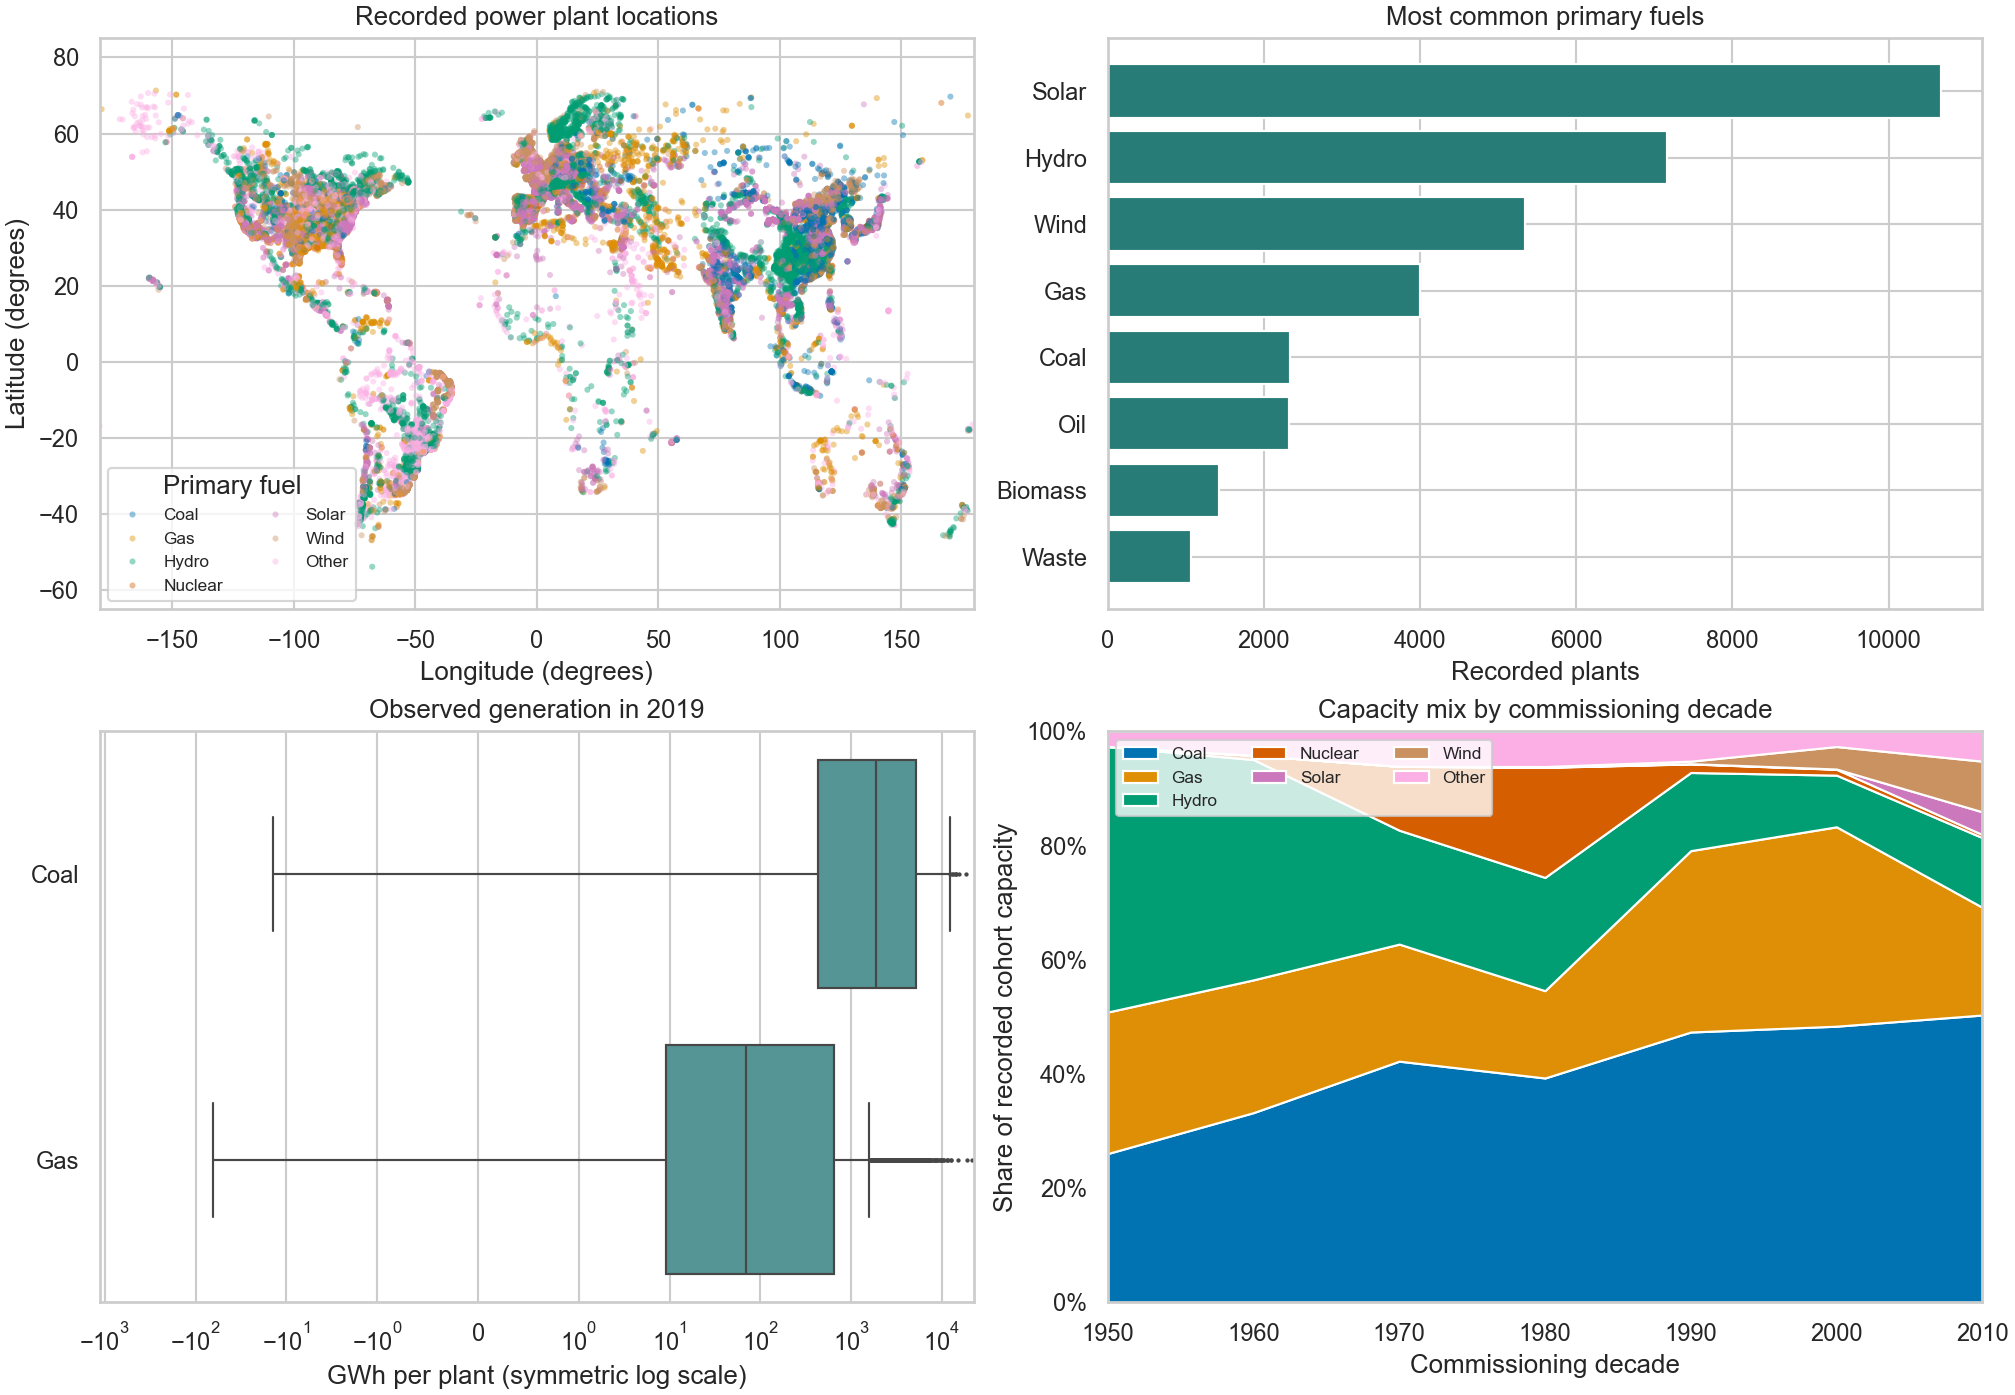

In [5]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")

# Show geographic coverage as longitude/latitude points by primary fuel group.
coordinates = plants[["longitude", "latitude"]].to_numpy()
mapped = plants.loc[np.isfinite(coordinates).all(axis=1)].copy()
mapped["fuel_group"] = np.where(mapped["primary_fuel"].isin(main_fuels),
                               mapped["primary_fuel"], "Other")
palette = dict(zip([*main_fuels, "Other"], sns.color_palette("colorblind", 7)))
sns.scatterplot(data=mapped, x="longitude", y="latitude", hue="fuel_group",
                hue_order=[*main_fuels, "Other"], palette=palette,
                alpha=0.42, s=8, linewidth=0, ax=axes[0, 0])
axes[0, 0].set(title="Recorded power plant locations", xlabel="Longitude (degrees)",
               ylabel="Latitude (degrees)", xlim=(-180, 180), ylim=(-65, 85))
axes[0, 0].legend(title="Primary fuel", fontsize=8, ncol=2, loc="lower left")

# Compare counts and show the generation distributions for the tested fuels.
top = fuel_counts.head(8).sort_values()
axes[0, 1].barh(top.index, top.values, color="#287c77")
axes[0, 1].set(title="Most common primary fuels", xlabel="Recorded plants")
compared = reporting.loc[reporting["primary_fuel"].isin(["Coal", "Gas"])]
sns.boxplot(data=compared, x=generation_column, y="primary_fuel", order=["Coal", "Gas"],
            color="#4a9fa1", fliersize=1, ax=axes[1, 0])
axes[1, 0].set_xscale("symlog", linthresh=1)
axes[1, 0].set(title=f"Observed generation in {generation_year}",
               xlabel="GWh per plant (symmetric log scale)", ylabel="")

# Pass the transposed NumPy array to stackplot: one row per fuel and one column per decade.
ordered_fuels = [fuel for fuel in [*main_fuels, "Other"] if fuel in capacity_share.columns]
axes[1, 1].stackplot(capacity_share.index, capacity_share[ordered_fuels].to_numpy().T,
                     labels=ordered_fuels, colors=[palette[fuel] for fuel in ordered_fuels])
axes[1, 1].set(title="Capacity mix by commissioning decade",
               xlabel="Commissioning decade", ylabel="Share of recorded cohort capacity",
               ylim=(0, 1), xlim=(1950, 2010))
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].legend(loc="upper left", ncol=3, fontsize=8)
fig.savefig("power_plant_charts.png", dpi=155)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# 6. Apply matrix operations and interpret eigenvectors

The example combines log capacity, commissioning year and a one-hot representation of primary fuel. Standardized numeric columns put MW and years on comparable scales. Fuel indicators receive a shared scale, so rare indicators do not each receive the same variance as a full numeric feature. This descriptive PCA depends on the chosen variables, transformations and plants with usable data.

In [6]:
# Create a matrix with one row per plant and one column per feature.
matrix_data = plants.loc[year_known & (capacity > 0)].dropna(subset=["primary_fuel"])
numeric = np.column_stack([np.log10(matrix_data["capacity_mw"]),
                           matrix_data["commissioning_year"]])
standardized = (numeric - numeric.mean(axis=0)) / numeric.std(axis=0, ddof=1)
fuel_labels = matrix_data["primary_fuel"]
fuel_labels = fuel_labels.where(fuel_labels.isin(main_fuels), "Other")
indicators = pd.get_dummies(fuel_labels, dtype=float)
fuel_array = indicators.to_numpy()
fuel_centered = fuel_array - fuel_array.mean(axis=0)
fuel_scaled = fuel_centered / np.sqrt(fuel_centered.var(axis=0, ddof=1).sum())
features = np.column_stack([standardized, fuel_scaled])
labels = ["Log capacity", "Commissioning year", *indicators.columns]

# Multiply by the transpose to get covariance; eigh handles symmetric matrices.
covariance = features.T @ features / (features.shape[0] - 1)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained = eigenvalues / eigenvalues.sum()

# The first eigenvector gives the feature weights on the main axis of variation.
# Its sign can flip as a group without changing the component's meaning.
pc1_weights = pd.Series(eigenvectors[:, 0], index=labels)
largest = pc1_weights.abs().nlargest(3).index
print(f"PCA complete cases: {len(matrix_data):,}; covariance shape: {covariance.shape}")
print(f"PC1 explains {explained[0]:.1%}; PC2 explains {explained[1]:.1%}.")
print("Largest PC1 weights:\n", pc1_weights.loc[largest].round(3).to_string())
print("Eigenvectors give directions of joint variation. Eigenvalues measure variance along them.")


PCA complete cases: 17,447; covariance shape: (9, 9)
PC1 explains 41.1%; PC2 explains 31.9%.
Largest PC1 weights:
 Commissioning year    0.692
Log capacity         -0.645
Solar                 0.239
Eigenvectors give directions of joint variation. Eigenvalues measure variance along them.


# 7. Integrate the libraries and summarize the results

Pandas reads, groups and pivots the data. NumPy masks filter the Pandas rows, NumPy arrays feed the chart, and NumPy matrix multiplication and eigendecomposition reveal joint patterns. Matplotlib and Seaborn render the charts. SciPy evaluates the comparison of observed mean generation.

In [7]:
# Use the computed results to write a concise, reproducible project README.
renewables = capacity_share[["Solar", "Wind"]].sum(axis=1)
readme = f"""# Global Power Plants | NumPy, Pandas and Matplotlib

This project answers all seven tasks in the NumPy Advanced Daily Challenge.
Open [the executed Jupyter notebook](global_power_plants.ipynb) for the code,
tables, figures, and explanations. Data source: [World Resources Institute,
Global Power Plant Database v1.3.0](https://datasets.wri.org/dataset/globalpowerplantdatabase), licensed CC BY 4.0.

## Findings

- The cleaned inventory contains **{len(plants):,} plants**.
  **{country_counts.index[0]}** has the most records ({country_counts.iloc[0]:,}),
  and **{fuel_counts.index[0]}** is the most common primary fuel ({fuel_counts.iloc[0]:,} plants).
- **{generation_year}** has the most usable observed generation records
  ({len(reporting):,}, or {len(reporting) / len(plants):.1%} of listed plants).
  Coal averaged **{coal.mean():,.1f} GWh** and gas averaged **{gas.mean():,.1f} GWh** per reporting plant.
  The coal-minus-gas difference was **{difference:,.1f} GWh** (95% CI
  {interval.low:,.1f} to {interval.high:,.1f} GWh, Welch p = {test.pvalue:.4g}).
  {decision}
- Solar and wind together represented **{renewables.loc[1990]:.1%}** of recorded
  capacity for plants commissioned in the 1990s and **{renewables.loc[2010]:.1%}**
  for the 2010s cohort. Commissioning year was available for {year_known.mean():.1%}
  of listed plants, and the cohort comparison reflects recorded capacity.
- The first principal component explains **{explained[0]:.1%}** of variance
  in the chosen feature matrix. Its largest absolute weights were
  {", ".join(largest)}. The eigenvector describes how the features vary
  together, and its eigenvalue measures variation along that direction.
  In this dataset, the weights associate later commissioning and solar
  with smaller installed capacity along that component.

[View the four charts](power_plant_charts.png)

The generation comparison applies to reporting plants. Size, geography and
reporting coverage may differ by fuel, so the result is descriptive.
The database is a versioned snapshot and the commissioning cohorts are
historical groups of plants represented in that snapshot.

## Reproduce locally

Keep the bundled WRI ZIP beside the notebook. Install
`jupyter numpy pandas scipy matplotlib seaborn` with pip, open the notebook
in Jupyter, and run all cells. The notebook regenerates the chart and README.
"""
Path("README.md").write_text(readme, encoding="utf-8")
print(readme)



# Global Power Plants | NumPy, Pandas and Matplotlib

This project answers all seven tasks in the NumPy Advanced Daily Challenge.
Open [the executed Jupyter notebook](global_power_plants.ipynb) for the code,
tables, figures, and explanations. Data source: [World Resources Institute,
Global Power Plant Database v1.3.0](https://datasets.wri.org/dataset/globalpowerplantdatabase), licensed CC BY 4.0.

## Findings

- The cleaned inventory contains **34,936 plants**.
  **United States of America** has the most records (9,833),
  and **Solar** is the most common primary fuel (10,665 plants).
- **2019** has the most usable observed generation records
  (9,659, or 27.6% of listed plants).
  Coal averaged **3,325.5 GWh** and gas averaged **890.2 GWh** per reporting plant.
  The coal-minus-gas difference was **2,435.2 GWh** (95% CI
  1,997.7 to 2,872.8 GWh, Welch p = 9.012e-24).
  Reject equal means at the 5% level.
- Solar and wind together represented **0.5%** of recorded
  capacity for plants 